<a href="https://colab.research.google.com/github/ElioAtlitec8888/NovaBot-Avance2/blob/main/01_nlp_y_clasificacion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install nltk scikit-learn pandas matplotlib seaborn

In [3]:
import pandas as pd
import nltk
import string

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import SnowballStemmer

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [5]:
nltk.download('punkt')
nltk.download('stopwords')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

In [9]:
df = pd.read_csv("novabot_intenciones.csv")

df.head()

,texto,intencion
0,¿Tienen leche?,consultar_producto
1,¿Venden yogurt?,consultar_producto
2,¿Hay refrescos disponibles?,consultar_producto
3,Estoy buscando queso.,consultar_producto
4,Necesito comprar pan.,consultar_producto


In [10]:
df.info()
df['intencion'].value_counts()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   texto      250 non-null    object
 1   intencion  250 non-null    object
dtypes: object(2)
memory usage: 4.0+ KB


,count
intencion,
consultar_producto,50
consultar_horario,50
estado_pedido,50
costo_envio,50
soporte,50


In [12]:
import string
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import SnowballStemmer

In [13]:
stop_words = set(stopwords.words('spanish'))

stemmer = SnowballStemmer('spanish')

In [14]:
def limpiar_texto(texto):

    texto = texto.lower()

    texto = texto.translate(
        str.maketrans('', '', string.punctuation)
    )

    tokens = word_tokenize(texto)

    tokens = [
        palabra
        for palabra in tokens
        if palabra not in stop_words
    ]

    tokens = [
        stemmer.stem(palabra)
        for palabra in tokens
    ]

    return " ".join(tokens)

In [16]:
import nltk

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [17]:
df["texto_procesado"] = df["texto"].apply(limpiar_texto)

In [18]:
df["texto_procesado"] = df["texto"].apply(limpiar_texto)

In [19]:
df[["texto","texto_procesado"]].head(10)

,texto,texto_procesado
0,¿Tienen leche?,¿tien lech
1,¿Venden yogurt?,¿vend yogurt
2,¿Hay refrescos disponibles?,¿hay refresc dispon
3,Estoy buscando queso.,busc ques
4,Necesito comprar pan.,necesit compr pan
5,¿Puedo encontrar cereales?,¿pued encontr cereal
6,¿Tienen mantequilla?,¿tien mantequill
7,¿Hay jugos en existencia?,¿hay jug existent
8,Busco una botella de agua.,busc botell agu
9,¿Manejan productos lácteos?,¿manej product lacte


In [20]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizador = TfidfVectorizer()

X = vectorizador.fit_transform(
    df["texto_procesado"]
)

y = df["intencion"]

In [22]:
print(X.shape)
print(vectorizador.get_feature_names_out()[:20])

(250, 277)
['24' 'abiert' 'abr' 'abren' 'acced' 'acces' 'aceit' 'acept' 'activ'
 'actual' 'actualiz' 'adicional' 'agu' 'algun' 'aliment' 'almacen'
 'almendr' 'apertur' 'aplic' 'apoy']


In [25]:
# --------------------------------------------------
# PASO 1: Dividir el dataset en entrenamiento y prueba
# --------------------------------------------------
#
# Objetivo:
# Separar los datos para que el modelo aprenda con una
# parte del dataset y posteriormente sea evaluado con
# ejemplos que nunca ha visto.
#
# X = vectores TF-IDF generados previamente
# y = etiquetas (intenciones)
#
# Se utilizará:
# - 80% para entrenamiento
# - 20% para prueba
#
# random_state=42 garantiza que la división sea
# reproducible en futuras ejecuciones.
# --------------------------------------------------

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Mostrar información de los conjuntos generados

print("Registros para entrenamiento:", X_train.shape[0])
print("Registros para prueba:", X_test.shape[0])

Registros para entrenamiento: 200
Registros para prueba: 50


In [26]:
# --------------------------------------------------
# PASO 2: Entrenamiento del clasificador
# --------------------------------------------------
#
# Se utilizará Multinomial Naive Bayes.
#
# Este algoritmo es ampliamente utilizado en tareas de:
# - Clasificación de texto
# - Procesamiento de Lenguaje Natural (NLP)
# - Clasificación de intenciones
#
# El modelo aprenderá patrones presentes en los vectores
# TF-IDF para asociarlos con las intenciones definidas.
# --------------------------------------------------

from sklearn.naive_bayes import MultinomialNB

# Crear instancia del modelo
modelo = MultinomialNB()

# Entrenar el modelo
modelo.fit(X_train, y_train)

print("Modelo entrenado correctamente.")

Modelo entrenado correctamente.


In [28]:
# --------------------------------------------------
# PASO 3: Generación de predicciones
# --------------------------------------------------
#
# Una vez entrenado el modelo, se utilizan los datos
# de prueba para verificar qué tan bien aprendió.
#
# El modelo intentará clasificar cada consulta dentro
# de una de las cinco intenciones definidas:
#
# - consultar_producto
# - consultar_horario
# - estado_pedido
# - costo_envio
# - soporte
# --------------------------------------------------

y_pred = modelo.predict(X_test)

print("Predicciones generadas correctamente.")

Predicciones generadas correctamente.


In [29]:
# --------------------------------------------------
# PASO 4: Calcular Accuracy
# --------------------------------------------------
#
# Accuracy representa el porcentaje de predicciones
# correctas realizadas por el modelo.
#
# Fórmula:
#
# Accuracy =
# Predicciones Correctas / Total de Predicciones
#
# Aunque es una métrica importante, no debe usarse
# como única medida de evaluación.
# --------------------------------------------------

from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy del modelo:", round(accuracy, 4))

Accuracy del modelo: 0.92


In [30]:
# --------------------------------------------------
# PASO 5: Métricas detalladas de evaluación
# --------------------------------------------------
#
# Precision:
# Indica qué tan confiables son las predicciones
# positivas realizadas por el modelo.
#
# Recall:
# Mide la capacidad del modelo para encontrar todos
# los ejemplos pertenecientes a una clase.
#
# F1 Score:
# Combina Precision y Recall en una única métrica.
#
# Estas métricas son especialmente importantes cuando
# existen clases desbalanceadas.
# --------------------------------------------------

from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred
    )
)

                    precision    recall  f1-score   support

 consultar_horario       1.00      0.71      0.83         7
consultar_producto       1.00      0.92      0.96        13
       costo_envio       1.00      1.00      1.00        11
     estado_pedido       0.77      1.00      0.87        10
           soporte       0.89      0.89      0.89         9

          accuracy                           0.92        50
         macro avg       0.93      0.91      0.91        50
      weighted avg       0.93      0.92      0.92        50



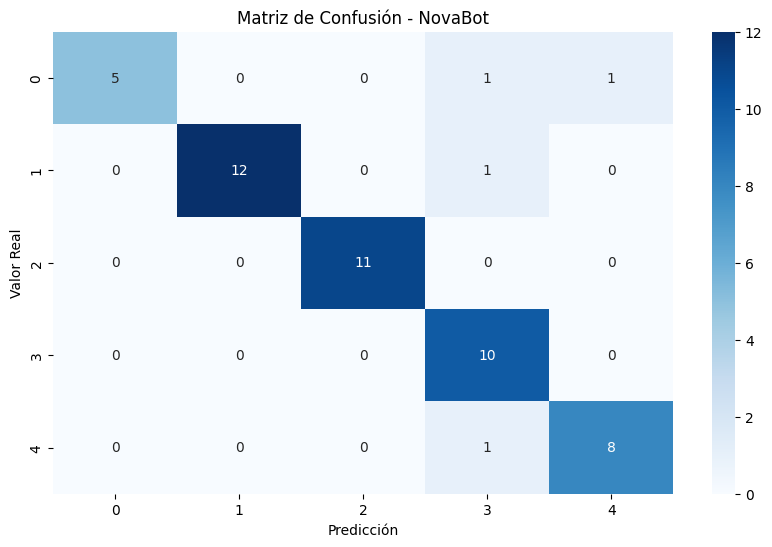

In [31]:
# --------------------------------------------------
# PASO 6: Generación de la matriz de confusión
# --------------------------------------------------
#
# La matriz de confusión permite visualizar:
#
# - Predicciones correctas
# - Predicciones incorrectas
# - Clases que generan confusión
#
# Los valores de la diagonal principal representan
# clasificaciones correctas.
#
# Valores fuera de la diagonal representan errores.
# --------------------------------------------------

from sklearn.metrics import confusion_matrix

import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(
    y_test,
    y_pred
)

plt.figure(figsize=(10, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("Matriz de Confusión - NovaBot")
plt.xlabel("Predicción")
plt.ylabel("Valor Real")

plt.show()

In [34]:
print(
    f"Accuracy del modelo: {accuracy:.4f}"
)

Accuracy del modelo: 0.9200


In [35]:
# =====================================================
# VISUALIZACION DE ALGUNAS PREDICCIONES
# =====================================================

resultado = pd.DataFrame({
    "Texto": df.iloc[y_test.index]["texto"],
    "Real": y_test,
    "Prediccion": y_pred
})

resultado.head(10)

,Texto,Real,Prediccion
142,¿Qué ocurre con mi orden?,estado_pedido,estado_pedido
6,¿Tienen mantequilla?,consultar_producto,consultar_producto
97,¿Cuál es la hora más temprana para comprar?,consultar_horario,consultar_horario
60,¿Trabajan los sábados?,consultar_horario,estado_pedido
112,¿Mi compra sigue pendiente?,estado_pedido,estado_pedido
181,¿Hay descuentos en el envío?,costo_envio,costo_envio
197,¿Hay algún costo adicional por entrega?,costo_envio,costo_envio
184,¿Qué debo pagar por el transporte?,costo_envio,costo_envio
9,¿Manejan productos lácteos?,consultar_producto,consultar_producto
104,¿Cuándo llegará mi compra?,estado_pedido,estado_pedido


In [36]:
# =====================================================
# REPORTE DE CLASIFICACION
# =====================================================
#
# Muestra:
# - Precision
# - Recall
# - F1-Score
# - Support
#
# para cada intención.
# =====================================================

from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred
    )
)

                    precision    recall  f1-score   support

 consultar_horario       1.00      0.71      0.83         7
consultar_producto       1.00      0.92      0.96        13
       costo_envio       1.00      1.00      1.00        11
     estado_pedido       0.77      1.00      0.87        10
           soporte       0.89      0.89      0.89         9

          accuracy                           0.92        50
         macro avg       0.93      0.91      0.91        50
      weighted avg       0.93      0.92      0.92        50



In [37]:
# =====================================================
# FUNCION PARA PROBAR NOVABOT
# =====================================================

def predecir_intencion(texto):

    texto_limpio = limpiar_texto(texto)

    vector = vectorizador.transform(
        [texto_limpio]
    )

    prediccion = modelo.predict(
        vector
    )[0]

    return prediccion

In [40]:
print(
    predecir_intencion(
        "¿Tienen leche deslactosada?"
    )
)
print(
    predecir_intencion(
        "¿Dónde está mi pedido?"
    )
)
print(
    predecir_intencion(
        "Necesito ayuda con mi cuenta"
    )
)
print(
    predecir_intencion(
        "¿Cuánto cuesta el envío?"
    )
)

consultar_producto
estado_pedido
soporte
costo_envio


In [41]:
# =====================================================
# GUARDAR EL MODELO ENTRENADO
# =====================================================
#
# Se utiliza pickle para almacenar el modelo
# entrenado en un archivo.
#
# Posteriormente podrá cargarse sin necesidad
# de volver a entrenar.
# =====================================================

import pickle

with open('modelo_texto.pkl', 'wb') as archivo:
    pickle.dump(modelo, archivo)

print("Modelo guardado correctamente")


Modelo guardado correctamente


In [42]:
# =====================================================
# GUARDAR EL VECTORIZADOR TF-IDF
# =====================================================

with open('vectorizador_tfidf.pkl', 'wb') as archivo:
    pickle.dump(vectorizador, archivo)

print("Vectorizador guardado correctamente")

Vectorizador guardado correctamente


In [43]:
import os

print(os.listdir())

['.config', 'vectorizador_tfidf.pkl', 'novabot_intenciones.csv', 'modelo_texto.pkl', 'drive', 'sample_data']


In [44]:
from google.colab import files

files.download('modelo_texto.pkl')
files.download('vectorizador_tfidf.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [45]:
texto = "¿Dónde está mi pedido?"

texto_limpio = limpiar_texto(texto)

vector = vectorizador.transform(
    [texto_limpio]
)

prediccion = modelo.predict(
    vector
)

print(prediccion[0])

estado_pedido


In [46]:
import os

for archivo in os.listdir():
    print(archivo)

.config
vectorizador_tfidf.pkl
novabot_intenciones.csv
modelo_texto.pkl
drive
sample_data


In [47]:
# =====================================================
# GUARDAR EL VECTORIZADOR TF-IDF
# =====================================================
#
# El vectorizador TF-IDF debe guardarse porque es el
# encargado de transformar texto en vectores.
#
# Cuando NovaBot reciba nuevas consultas, deberá usar
# exactamente este mismo vectorizador.
# =====================================================

import pickle

with open('vectorizador_tfidf.pkl', 'wb') as archivo:
    pickle.dump(vectorizador, archivo)

print("Vectorizador guardado correctamente.")

Vectorizador guardado correctamente.


In [48]:
import os

for archivo in os.listdir():
    print(archivo)

.config
vectorizador_tfidf.pkl
novabot_intenciones.csv
modelo_texto.pkl
drive
sample_data


In [50]:
from google.colab import files

files.download('modelo_texto.pkl')
files.download('vectorizador_tfidf.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [51]:
print(os.listdir())

['.config', 'vectorizador_tfidf.pkl', 'novabot_intenciones.csv', 'modelo_texto.pkl', 'drive', 'sample_data']


In [52]:
# =====================================================
# FUNCION PARA PREDECIR LA INTENCION DE UNA CONSULTA
# =====================================================
#
# Esta función recibe una consulta escrita por un usuario,
# aplica exactamente el mismo proceso de limpieza utilizado
# durante el entrenamiento y posteriormente predice la
# intención utilizando el modelo entrenado.
#
# Flujo:
#
# Texto
# ↓
# Limpieza NLP
# ↓
# TF-IDF
# ↓
# Naive Bayes
# ↓
# Intención
# =====================================================

def predecir_intencion(texto):

    # Limpiar texto utilizando la función creada anteriormente
    texto_limpio = limpiar_texto(texto)

    # Transformar el texto a representación TF-IDF
    vector = vectorizador.transform(
        [texto_limpio]
    )

    # Realizar predicción
    prediccion = modelo.predict(vector)

    return prediccion[0]

In [57]:
print(
    predecir_intencion(
        "¿tengo problemas?"
    )
)

soporte


In [58]:
consulta = input("Escribe una consulta para NovaBot: ")

resultado = predecir_intencion(
    consulta
)

print("Intención detectada:", resultado)

Escribe una consulta para NovaBot: tiene refresco?
Intención detectada: consultar_producto
